# Reproducible yield walkthrough

This notebook is a compact, Colab-friendly walkthrough of the public agronomic dataset. It is deliberately descriptive. The unresolved whole-plot/block structure means that plot-level comparisons are not treated as confirmatory causal effects.

**Workflow**

1. Read the canonical clean data.
2. Check the expected 32-plot structure.
3. Parse compact plot identifiers independently.
4. Use Pandas to inspect, transform, group, and aggregate the data.
5. Reshape a treatment summary.
6. Produce a transparent descriptive figure.
7. State what cannot be inferred from these rows.


In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    # Useful when the notebook is launched from analysis/notebooks/
    ROOT = ROOT.parents[1]

DATA = ROOT / "data" / "derived" / "plot_outcomes_clean.csv"
d = pd.read_csv(DATA)
d.head()

,plot_code,tillage_code,irrigation_code,fertilizer_code,replicate_code,tillage_label,irrigation_label,plant_height_cm_early,panicles_0_25m2,productive_tillers_m2,plant_height_cm_harvest,fresh_weight_kg_plot,ten_panicle_weight_g,thousand_seed_weight_g,filled_grain_count,filled_grain_weight_g,unfilled_grain_count,unfilled_grain_weight_g,dry_yield_kg_plot
0,L1IR1F1R1,L1,IR1,F1,R1,two_ploughings_conventional,normal_irrigation,48.1,68,272,111.6,12.90,49.0,25.3,1777,44.5,412,0.2,9.30
1,L1IR1F1R2,L1,IR1,F1,R2,two_ploughings_conventional,normal_irrigation,51.4,63,252,97.4,14.55,37.1,27.3,1210,33.1,250,1.3,11.35
2,L1IR1F2R1,L1,IR1,F2,R1,two_ploughings_conventional,normal_irrigation,49.5,60,238,109.2,13.50,48.6,24.6,1854,45.4,301,1.7,10.00
3,L1IR1F2R2,L1,IR1,F2,R2,two_ploughings_conventional,normal_irrigation,51.4,85,338,93.0,12.95,51.8,24.5,1930,47.3,205,0.9,10.50
4,L1IR1F3R1,L1,IR1,F3,R1,two_ploughings_conventional,normal_irrigation,43.9,75,300,95.6,10.95,43.2,35.0,1600,40.1,315,1.9,8.30


## 1. Inspect before analysing

The first check is structural: dimensions, column names, types, missingness, and unique plot identifiers. This is preferable to immediately running a model on an unfamiliar table.


In [2]:
print("shape:", d.shape)
print("unique plots:", d["plot_code"].nunique())
print("missing dry-yield values:", d["dry_yield_kg_plot"].isna().sum())
display(d.dtypes.to_frame("dtype"))
display(d.iloc[:5, :8])  # integer-location indexing
display(d.loc[d["irrigation_code"].eq("IR2"), ["plot_code", "dry_yield_kg_plot"]].head())

shape: (32, 19)
unique plots: 32
missing dry-yield values: 0


,dtype
plot_code,object
tillage_code,object
irrigation_code,object
fertilizer_code,object
replicate_code,object
tillage_label,object
irrigation_label,object
plant_height_cm_early,float64
panicles_0_25m2,int64
productive_tillers_m2,int64


,plot_code,tillage_code,irrigation_code,fertilizer_code,replicate_code,tillage_label,irrigation_label,plant_height_cm_early
0,L1IR1F1R1,L1,IR1,F1,R1,two_ploughings_conventional,normal_irrigation,48.1
1,L1IR1F1R2,L1,IR1,F1,R2,two_ploughings_conventional,normal_irrigation,51.4
2,L1IR1F2R1,L1,IR1,F2,R1,two_ploughings_conventional,normal_irrigation,49.5
3,L1IR1F2R2,L1,IR1,F2,R2,two_ploughings_conventional,normal_irrigation,51.4
4,L1IR1F3R1,L1,IR1,F3,R1,two_ploughings_conventional,normal_irrigation,43.9


,plot_code,dry_yield_kg_plot
8,L1IR2F1R1,7.75
9,L1IR2F1R2,10.85
10,L1IR2F2R1,11.85
11,L1IR2F2R2,9.80
12,L1IR2F3R1,7.75


## 2. Parse the experimental code

The parser is intentionally strict. A malformed identifier should fail rather than be silently interpreted.


In [3]:
CODE_RE = re.compile(r"^(L[12])(IR[12])(F[1-4])(R[12])$")

def parse_plot_code(code: str) -> tuple[str, str, str, str]:
    match = CODE_RE.fullmatch(str(code).strip())
    if match is None:
        raise ValueError(f"Unexpected plot code: {code!r}")
    return match.groups()

parsed = d["plot_code"].apply(parse_plot_code)
parsed_df = pd.DataFrame(
    parsed.tolist(),
    columns=["parsed_L", "parsed_IR", "parsed_F", "parsed_R"],
    index=d.index,
)

checks = pd.concat([d, parsed_df], axis=1)
assert (checks["tillage_code"] == checks["parsed_L"]).all()
assert (checks["irrigation_code"] == checks["parsed_IR"]).all()
assert (checks["fertilizer_code"] == checks["parsed_F"]).all()
assert (checks["replicate_code"] == checks["parsed_R"]).all()
print("All 32 compact identifiers agree with the explicit factor columns.")

All 32 compact identifiers agree with the explicit factor columns.


## 3. Transform and summarize with Pandas

`assign`, `np.where`, filtering, `groupby`, and `agg` are used here on the actual research data rather than on a toy dataset.


In [4]:
analysis = (
    d.assign(
        water_regime=np.where(
            d["irrigation_code"].eq("IR2"),
            "AWD",
            "normal irrigation",
        )
    )
    .dropna(subset=["dry_yield_kg_plot"])
)

marginal = (
    analysis
    .groupby(["tillage_code"], as_index=False)
    .agg(
        n=("dry_yield_kg_plot", "size"),
        mean_kg_plot=("dry_yield_kg_plot", "mean"),
        sd_kg_plot=("dry_yield_kg_plot", "std"),
    )
)

cells = (
    analysis
    .groupby(["tillage_code", "irrigation_code", "fertilizer_code"], as_index=False)
    .agg(
        n=("dry_yield_kg_plot", "size"),
        mean_kg_plot=("dry_yield_kg_plot", "mean"),
    )
)

display(marginal)
display(cells)

,tillage_code,n,mean_kg_plot,sd_kg_plot
0,L1,16,9.4125,1.701421
1,L2,16,7.1625,2.297934


,tillage_code,irrigation_code,fertilizer_code,n,mean_kg_plot
0,L1,IR1,F1,2,10.325
1,L1,IR1,F2,2,10.250
2,L1,IR1,F3,2,10.350
3,L1,IR1,F4,2,8.125
4,L1,IR2,F1,2,9.300
5,L1,IR2,F2,2,10.825
6,L1,IR2,F3,2,8.675
7,L1,IR2,F4,2,7.450
8,L2,IR1,F1,2,9.950
9,L2,IR1,F2,2,9.850


## 4. Wide and long representations

Long data are usually easier to analyse and plot. Wide tables can still be useful for compact comparison. The operation below makes the transformation explicit.


In [5]:
cell_wide = cells.pivot(
    index=["tillage_code", "irrigation_code"],
    columns="fertilizer_code",
    values="mean_kg_plot",
)
display(cell_wide)

fertilizer_code                   F1      F2      F3     F4
tillage_code irrigation_code                               
L1           IR1              10.325  10.250  10.350  8.125
             IR2               9.300  10.825   8.675  7.450
L2           IR1               9.950   9.850   6.375  5.425
             IR2               7.925   8.650   5.700  3.425

## 5. Descriptive visualization

The figure shows every plot and the group mean. It intentionally avoids inferential error bars because the correct error strata depend on the unresolved field randomization structure.


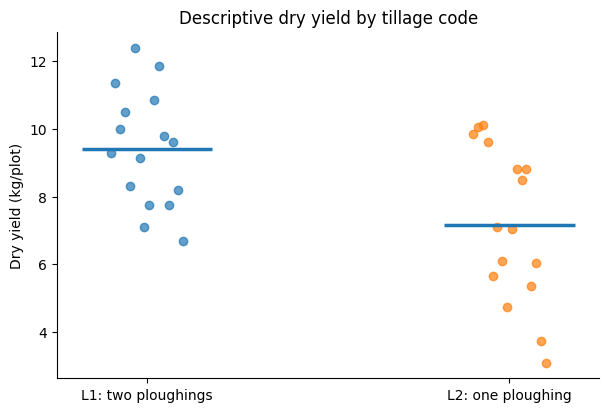

In [6]:
levels = ["L1", "L2"]
fig, ax = plt.subplots(figsize=(7.0, 4.5))

for i, level in enumerate(levels):
    values = analysis.loc[
        analysis["tillage_code"].eq(level),
        "dry_yield_kg_plot",
    ].to_numpy()
    offsets = np.linspace(-0.10, 0.10, len(values))
    ax.scatter(np.full(len(values), i) + offsets, values, alpha=0.7)
    ax.hlines(values.mean(), i - 0.18, i + 0.18, linewidth=2.5)

ax.set_xticks([0, 1], ["L1: two ploughings", "L2: one ploughing"])
ax.set_ylabel("Dry yield (kg/plot)")
ax.set_title("Descriptive dry yield by tillage code")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Interpretation boundary

The dataset directly supports descriptive differences among the observed coded groups. It does **not** by itself establish that tillage and irrigation were independently replicated at the assignment level. Therefore this notebook does not convert the group means into causal treatment effects, and it does not treat lower yield under reduced tillage as a VM0042 additionality result.

The greenhouse-gas series needed for seasonal CH₄, N₂O, CO₂ or CO₂e calculations are also absent from the public package. Those analyses remain intentionally unimplemented until the underlying chamber measurements and QA/QC information are available.
